
# LapWorth: Exploratory Data Analysis (EDA)

## Machine Learning-Based Used Laptop Price Estimation System

### 1. Introduction

Exploratory Data Analysis (EDA) is an important stage in the machine learning development process. It involves examining, summarising and visualising a dataset to understand its structure, characteristics, patterns and potential inconsistencies before model development.

This notebook focuses on analysing the laptop pricing dataset used in the LapWorth project. The analysis will examine laptop brands, product types, specifications, price distributions and relationships between laptop features and prices.

### Objectives

- Understand the structure and composition of the dataset.
- Examine the distribution of laptop brands and product categories.
- Analyse laptop price distributions.
- Investigate the relationships between RAM, processors, storage and laptop prices.
- Identify potential outliers and data quality issues.
- Produce meaningful visualisations and findings to support machine learning model development.

The findings from this analysis will serve as a foundation for subsequent model training, feature selection and evaluation.


In [91]:
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [92]:
import pandas as pd
df = pd.read_csv("data/raw/laptop_price.csv", encoding="latin1")
df.rename(columns={"Price_ngn": "price_ngn"}, inplace=True)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [93]:
# Display the first five rows
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,price_ngn
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1998469.16
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,1340984.76
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,857750.50
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,3785215.66
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,2690502.26


In [94]:
# Get the number of rows and columns
rows, columns = df.shape

print(f"Number of laptop records: {rows}")
print(f"Number of columns: {columns}")

Number of laptop records: 1303
Number of columns: 13


In [95]:
# Display all column names
df.columns

Index(['laptop_ID', 'Company', 'Product', 'TypeName', 'Inches',
       'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight',
       'price_ngn'],
      dtype='str')

In [96]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   str    
 2   Product           1303 non-null   str    
 3   TypeName          1303 non-null   str    
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   str    
 6   Cpu               1303 non-null   str    
 7   Ram               1303 non-null   str    
 8   Memory            1303 non-null   str    
 9   Gpu               1303 non-null   str    
 10  OpSys             1303 non-null   str    
 11  Weight            1303 non-null   str    
 12  price_ngn         1303 non-null   float64
dtypes: float64(2), int64(1), str(10)
memory usage: 132.5 KB


In [97]:
# Check for missing values in each column
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

Missing values per column:
laptop_ID           0
Company             0
Product             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
price_ngn           0
dtype: int64


In [98]:
# Calculate missing value percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage (%)': missing_percentage
})

missing_summary

,Missing Values,Missing Percentage (%)
laptop_ID,0,0.0
Company,0,0.0
Product,0,0.0
TypeName,0,0.0
Inches,0,0.0
ScreenResolution,0,0.0
Cpu,0,0.0
Ram,0,0.0
Memory,0,0.0
Gpu,0,0.0


In [99]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print(f"Total duplicate rows: {duplicate_count}")

Total duplicate rows: 0


In [100]:
# Display duplicate rows if present
df[df.duplicated()]

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,price_ngn


In [101]:
# Display data types of all columns
df.dtypes

laptop_ID             int64
Company                 str
Product                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                     str
Memory                  str
Gpu                     str
OpSys                   str
Weight                  str
price_ngn           float64
dtype: object

In [102]:
# Statistical summary of numerical columns
df.describe()

,laptop_ID,Inches,price_ngn
count,1303.000000,1303.000000,1.303000e+03
mean,660.155794,15.017191,1.676249e+06
std,381.172104,1.426304,1.042740e+06
min,1.000000,10.100000,2.595628e+05
25%,331.500000,14.000000,8.935523e+05
50%,659.000000,15.600000,1.457430e+06
75%,990.500000,15.600000,2.219530e+06
max,1320.000000,18.400000,9.098122e+06


In [103]:
# Examine unique values in selected categorical columns
categorical_columns = [
    'Company',
    'TypeName',
    'OpSys'
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts())


--- Company ---
Company
Dell         297
Lenovo       297
HP           274
Asus         158
Acer         103
MSI           54
Toshiba       48
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
Fujitsu        3
LG             3
Huawei         2
Name: count, dtype: int64

--- TypeName ---
TypeName
Notebook              727
Gaming                205
Ultrabook             196
2 in 1 Convertible    121
Workstation            29
Netbook                25
Name: count, dtype: int64

--- OpSys ---
OpSys
Windows 10      1072
No OS             66
Linux             62
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: count, dtype: int64


In [104]:
# Examine RAM and Weight values
print("RAM values:")
print(df['Ram'].unique())

print("\nWeight values:")
print(df['Weight'].unique())

RAM values:
<StringArray>
['8GB', '16GB', '4GB', '2GB', '12GB', '6GB', '32GB', '24GB', '64GB']
Length: 9, dtype: str

Weight values:
<StringArray>
[ '1.37kg',  '1.34kg',  '1.86kg',  '1.83kg',   '2.1kg',  '2.04kg',   '1.3kg',
   '1.6kg',   '2.2kg',  '0.92kg',
 ...
     '4kg',   '3.0kg',  '0.99kg',  '3.52kg', '2.591kg',  '2.21kg',   '3.3kg',
 '2.191kg',  '2.34kg',   '4.0kg']
Length: 179, dtype: str


In [105]:
# Examine storage configurations
print(df['Memory'].value_counts())

Memory
256GB SSD                        412
1TB HDD                          223
500GB HDD                        132
512GB SSD                        118
128GB SSD +  1TB HDD              94
128GB SSD                         76
256GB SSD +  1TB HDD              73
32GB Flash Storage                38
2TB HDD                           16
64GB Flash Storage                15
512GB SSD +  1TB HDD              14
1TB SSD                           14
256GB SSD +  2TB HDD              10
1.0TB Hybrid                       9
256GB Flash Storage                8
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          5
128GB Flash Storage                4
16GB SSD                           3
512GB SSD +  2TB HDD               3
256GB SSD +  256GB SSD             2
256GB SSD +  500GB HDD             2
128GB SSD +  2TB HDD               2
1TB SSD +  1TB HDD                 2
512GB Flash Storage                2
64GB SSD                       

In [106]:
# Count the number of laptops produced by each company
company_counts = df['Company'].value_counts()

company_counts

Company
Dell         297
Lenovo       297
HP           274
Asus         158
Acer         103
MSI           54
Toshiba       48
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
Fujitsu        3
LG             3
Huawei         2
Name: count, dtype: int64

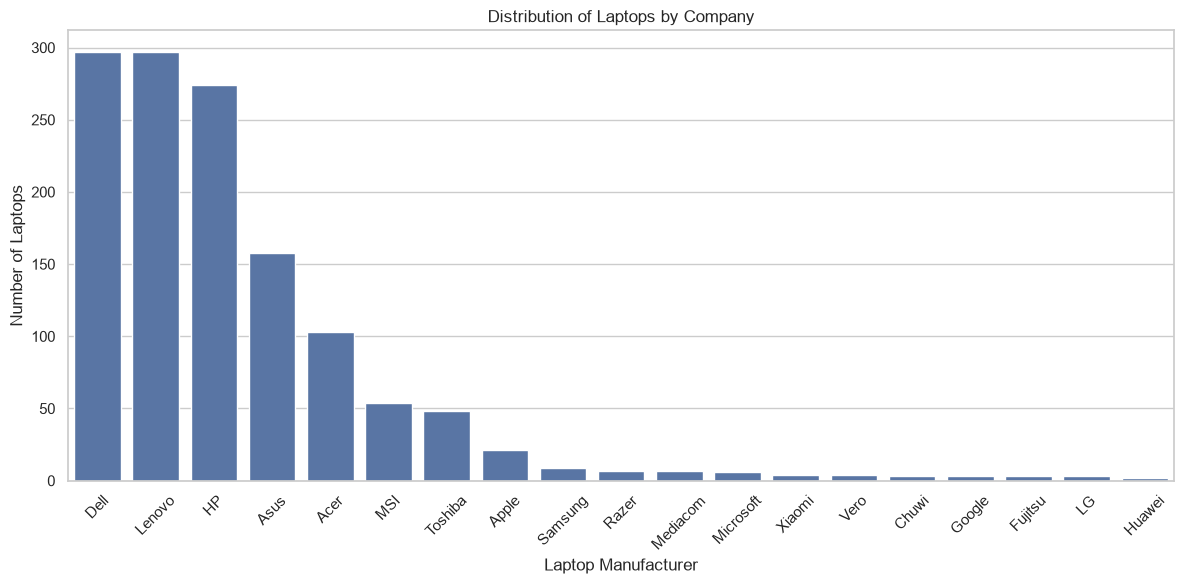

In [107]:
# Visualize laptop counts by company
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='Company',
    order=df['Company'].value_counts().index
)

plt.title('Distribution of Laptops by Company')
plt.xlabel('Laptop Manufacturer')
plt.ylabel('Number of Laptops')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [108]:
# Calculate the percentage distribution of companies
company_percentage = (
    df['Company'].value_counts(normalize=True) * 100
)

company_percentage.round(2)

Company
Dell         22.79
Lenovo       22.79
HP           21.03
Asus         12.13
Acer          7.90
MSI           4.14
Toshiba       3.68
Apple         1.61
Samsung       0.69
Razer         0.54
Mediacom      0.54
Microsoft     0.46
Xiaomi        0.31
Vero          0.31
Chuwi         0.23
Google        0.23
Fujitsu       0.23
LG            0.23
Huawei        0.15
Name: proportion, dtype: float64

In [109]:
# Count laptop types
type_counts = df['TypeName'].value_counts()

type_counts

TypeName
Notebook              727
Gaming                205
Ultrabook             196
2 in 1 Convertible    121
Workstation            29
Netbook                25
Name: count, dtype: int64

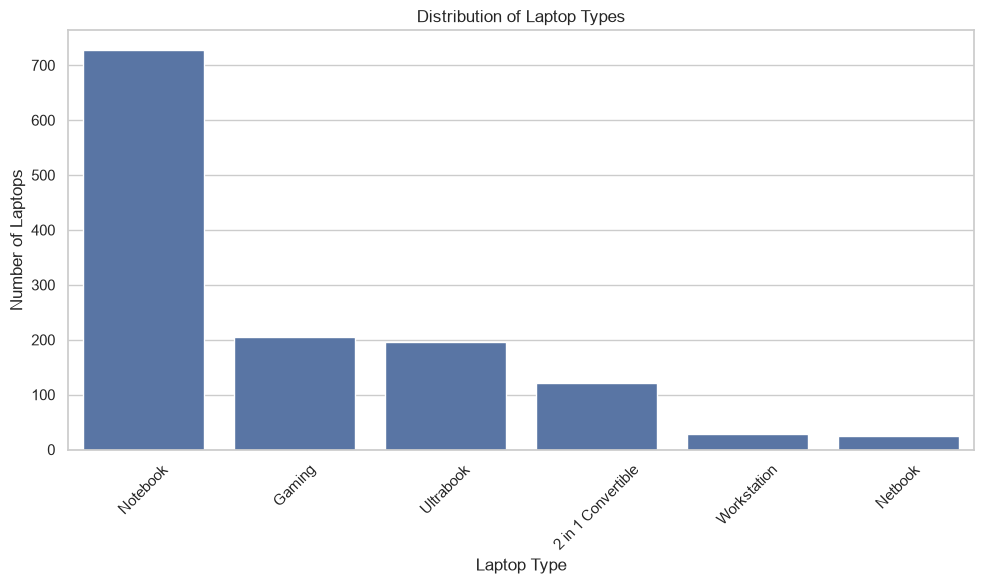

In [110]:
# Plot the distribution of laptop types
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='TypeName',
    order=df['TypeName'].value_counts().index
)

plt.title('Distribution of Laptop Types')
plt.xlabel('Laptop Type')
plt.ylabel('Number of Laptops')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [111]:
# Calculate laptop type percentages
type_percentage = (
    df['TypeName'].value_counts(normalize=True) * 100
)

type_percentage.round(2)

TypeName
Notebook              55.79
Gaming                15.73
Ultrabook             15.04
2 in 1 Convertible     9.29
Workstation            2.23
Netbook                1.92
Name: proportion, dtype: float64

In [112]:
# Examine the price column
df['price_ngn'].describe()

count    1.303000e+03
mean     1.676249e+06
std      1.042740e+06
min      2.595628e+05
25%      8.935523e+05
50%      1.457430e+06
75%      2.219530e+06
max      9.098122e+06
Name: price_ngn, dtype: float64

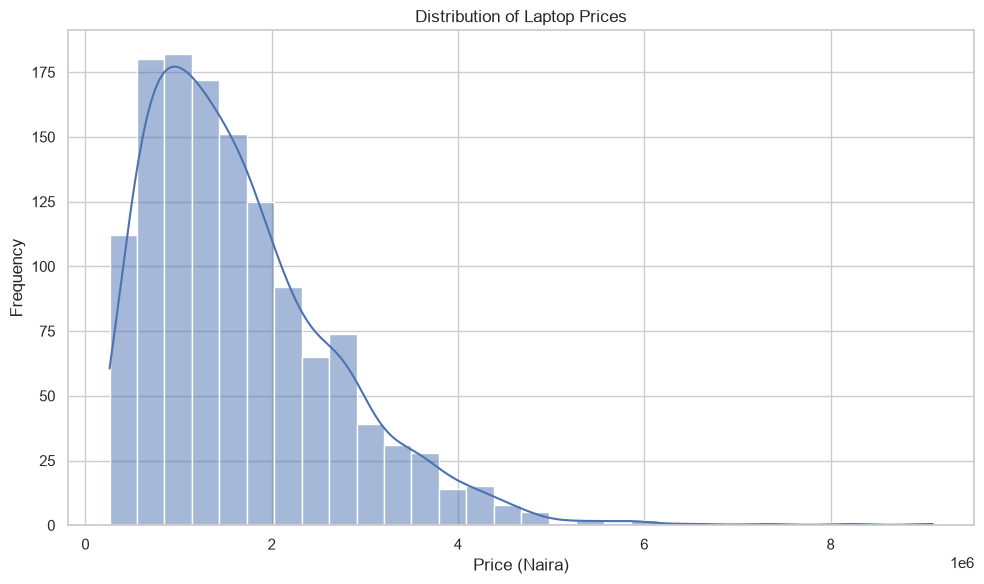

In [113]:
# Plot laptop price distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='price_ngn',
    bins=30,
    kde=True
)

plt.title('Distribution of Laptop Prices')
plt.xlabel('Price (Naira)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

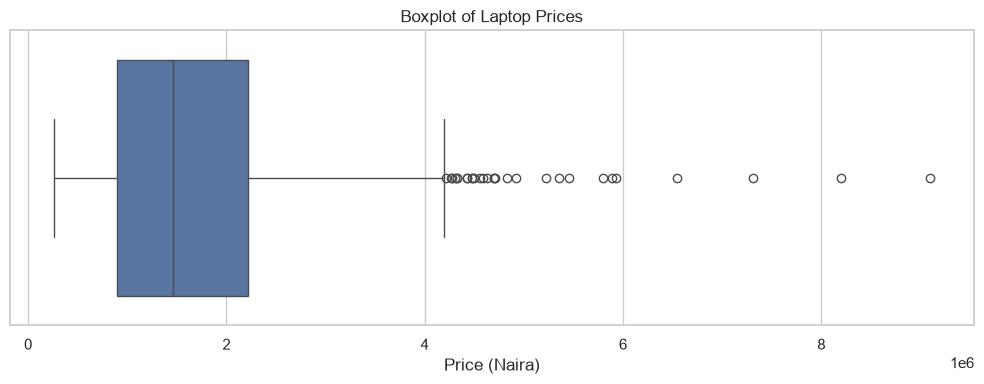

In [114]:
# Visualize price spread and potential outliers
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['price_ngn'])

plt.title('Boxplot of Laptop Prices')
plt.xlabel('Price (Naira)')

plt.tight_layout()
plt.show()

In [115]:
# Calculate price skewness
price_skewness = df['price_ngn'].skew()

print(f"Price skewness: {price_skewness:.3f}")

Price skewness: 1.521


### Findings from Univariate Analysis

#### Laptop Manufacturers

The analysis of laptop manufacturers revealed that Dell and Lenovo had the highest number of laptop records, with 297 records each, while Huawei had the lowest, with 2 records. The distribution is concentrated among a few manufacturers: the top five companies account for most of the 1,303 records.

#### Laptop Types

The analysis of laptop types showed that Notebook was the most represented category, with 727 records, while Netbook was the least represented, with 25 records. This indicates that the dataset is dominated by standard notebooks, with relatively fewer netbooks, workstations, and 2-in-1 convertible laptops.

#### Laptop Prices

The price distribution revealed that laptop prices ranged from ₦259,562.76 to ₦9,098,122.26, with a mean price of ₦1,676,248.83 and a median price of ₦1,457,429.98.

The histogram and boxplot indicate that the price distribution is strongly right-skewed, with a skewness value of 1.521. The mean is higher than the median, and several high-priced observations appear as potential outliers on the upper end of the distribution.

These observations provide an initial understanding of the dataset's composition and price variation, which will guide subsequent analysis of the relationships between laptop specifications and prices.

In [116]:
# Extract numerical RAM capacity in GB
df['ram_gb'] = (
    df['Ram']
    .astype(str)
    .str.extract(r'(\d+)')
    .astype(float)
)

# Display RAM and extracted values
df[['Ram', 'ram_gb']].head(10)

,Ram,ram_gb
0,8GB,8.0
1,8GB,8.0
2,8GB,8.0
3,16GB,16.0
4,8GB,8.0
5,4GB,4.0
6,16GB,16.0
7,8GB,8.0
8,16GB,16.0
9,8GB,8.0


In [117]:
# Confirm that our converted price column exists
print(df['price_ngn'].describe())

count    1.303000e+03
mean     1.676249e+06
std      1.042740e+06
min      2.595628e+05
25%      8.935523e+05
50%      1.457430e+06
75%      2.219530e+06
max      9.098122e+06
Name: price_ngn, dtype: float64


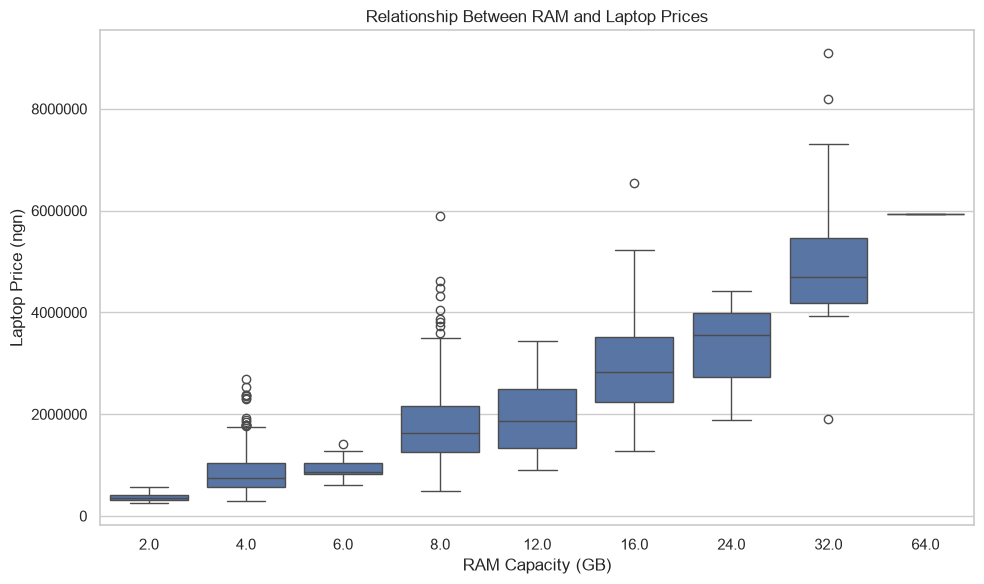

In [118]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='ram_gb',
    y='price_ngn'
)

plt.title('Relationship Between RAM and Laptop Prices')
plt.xlabel('RAM Capacity (GB)')
plt.ylabel('Laptop Price (ngn)')

plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

In [119]:
ram_price = df.groupby('ram_gb')['price_ngn'].agg(
    ['count', 'mean', 'median']
).round(2)

ram_price

,count,mean,median
ram_gb,,,
2.0,22,379454.58,349067.16
4.0,375,857112.75,742886.52
6.0,41,917727.91,863717.46
8.0,619,1761465.90,1639422.26
12.0,25,1848919.84,1863183.26
16.0,200,2889159.00,2820134.47
24.0,3,3291275.69,3553324.68
32.0,17,5091436.73,4695057.72
64.0,1,5929666.50,5929666.50


In [120]:
# Extract processor manufacturer
df['processor_brand'] = (
    df['Cpu']
    .astype(str)
    .str.split()
    .str[0]
)

df['processor_brand'].value_counts()

processor_brand
Intel      1240
AMD          62
Samsung       1
Name: count, dtype: int64

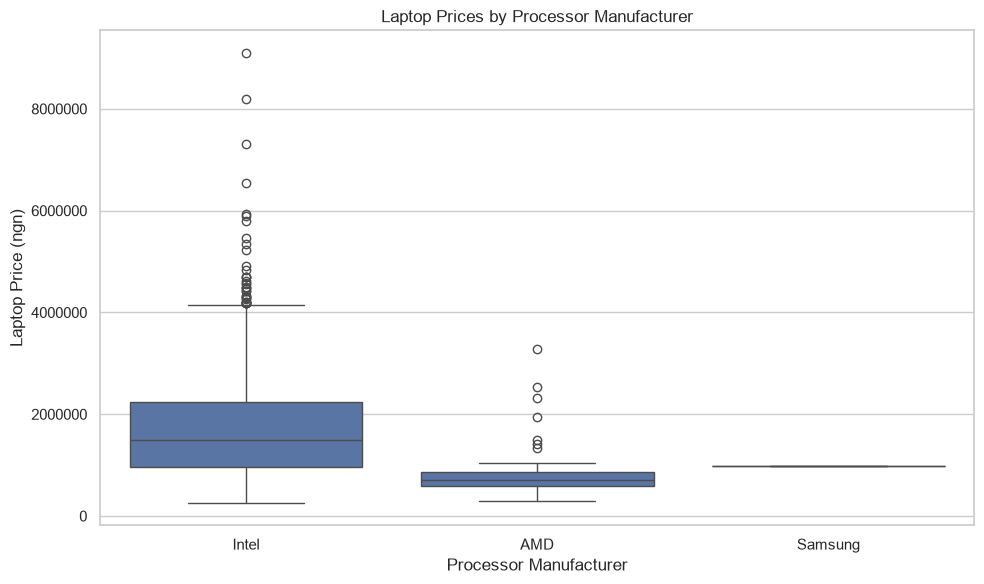

In [121]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='processor_brand',
    y='price_ngn'
)

plt.title('Laptop Prices by Processor Manufacturer')
plt.xlabel('Processor Manufacturer')
plt.ylabel('Laptop Price (ngn)')

plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

In [122]:
processor_price = df.groupby('processor_brand')['price_ngn'].agg(
    ['count', 'mean', 'median']
).round(2)

processor_price

,count,mean,median
processor_brand,,,
AMD,62,836327.43,707002.72
Intel,1240,1718803.93,1490248.26
Samsung,1,983056.66,983056.66


In [123]:
# Count storage configurations
storage_counts = df['Memory'].value_counts()

storage_counts.head(15)

Memory
256GB SSD               412
1TB HDD                 223
500GB HDD               132
512GB SSD               118
128GB SSD +  1TB HDD     94
128GB SSD                76
256GB SSD +  1TB HDD     73
32GB Flash Storage       38
2TB HDD                  16
64GB Flash Storage       15
512GB SSD +  1TB HDD     14
1TB SSD                  14
256GB SSD +  2TB HDD     10
1.0TB Hybrid              9
256GB Flash Storage       8
Name: count, dtype: int64

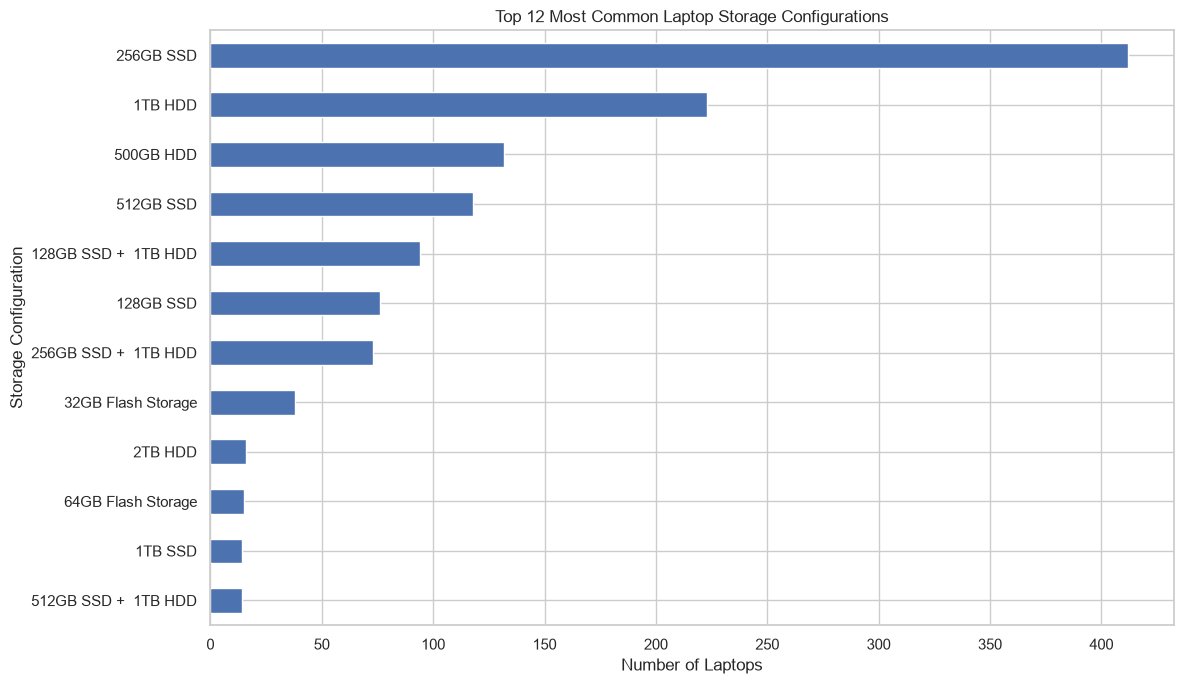

In [124]:
plt.figure(figsize=(12, 7))

storage_counts.head(12).sort_values().plot(
    kind='barh'
)

plt.title('Top 12 Most Common Laptop Storage Configurations')
plt.xlabel('Number of Laptops')
plt.ylabel('Storage Configuration')

plt.tight_layout()
plt.show()

In [125]:
storage_price = df.groupby('Memory')['price_ngn'].agg(
    ['count', 'mean', 'median']
).sort_values(by='mean', ascending=False).round(2)

storage_price.head(15)

,count,mean,median
Memory,,,
1TB SSD + 1TB HDD,2,5406214.94,5406214.94
512GB SSD + 1.0TB Hybrid,1,4833237.60,4833237.60
240GB SSD,1,4624394.00,4624394.00
1TB SSD,14,4582625.28,3926259.68
256GB SSD + 1.0TB Hybrid,1,4102270.08,4102270.08
512GB SSD + 1TB HDD,14,3730017.02,3899408.36
8GB SSD,1,3354923.26,3354923.26
64GB Flash Storage + 1TB HDD,1,2973037.82,2973037.82
512GB SSD,118,2775846.23,2788807.93


In [126]:
company_price = df.groupby('Company')['price_ngn'].agg(
    ['count', 'mean', 'median']
).sort_values(by='mean', ascending=False).round(2)

company_price

,count,mean,median
Company,,,
Razer,7,4991575.15,4324554.26
LG,3,3131162.26,3131162.26
MSI,54,2579081.44,2385292.26
Google,3,2502642.47,2325622.66
Microsoft,6,2405144.83,2341285.93
Apple,21,2333377.58,1998469.16
Huawei,2,2124237.76,2124237.76
Samsung,9,2108491.62,2459879.26
Toshiba,48,1891246.62,1807243.01


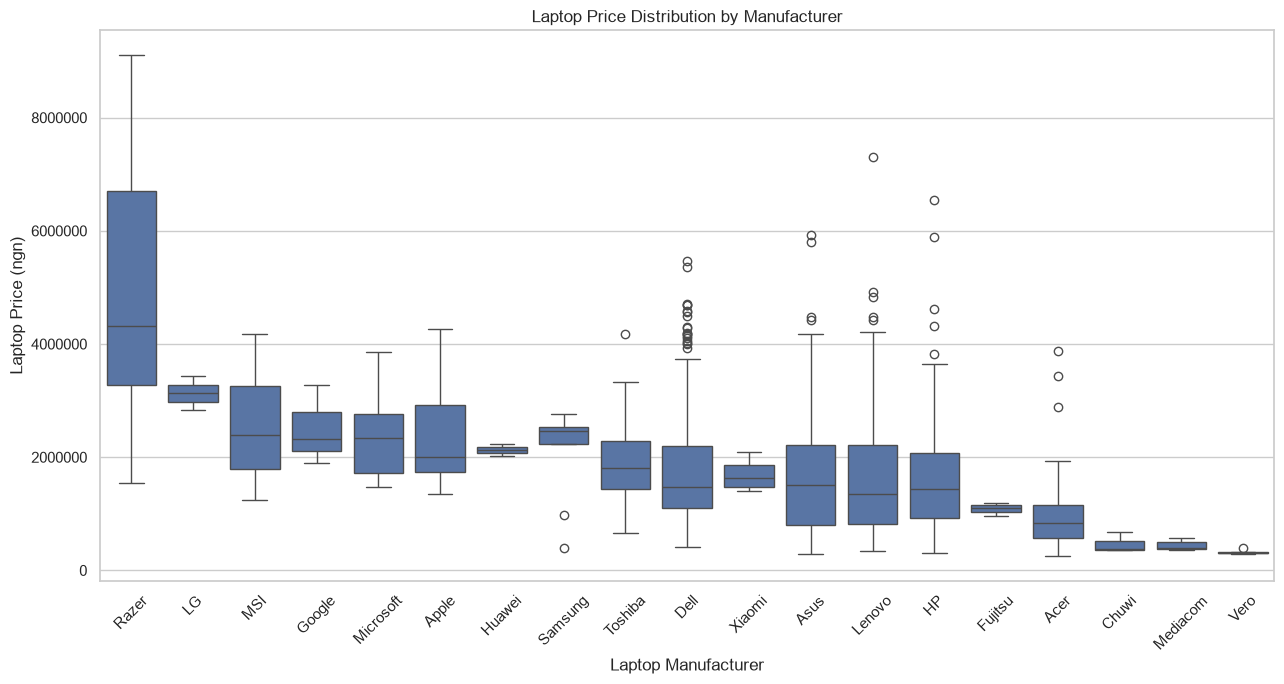

In [127]:
plt.figure(figsize=(13, 7))

sns.boxplot(
    data=df,
    x='Company',
    y='price_ngn',
    order=company_price.index
)

plt.title('Laptop Price Distribution by Manufacturer')
plt.xlabel('Laptop Manufacturer')
plt.ylabel('Laptop Price (ngn)')

plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

In [128]:
type_price = df.groupby('TypeName')['price_ngn'].agg(
    ['count', 'mean', 'median']
).sort_values(by='mean', ascending=False).round(2)

type_price

,count,mean,median
TypeName,,,
Workstation,29,3401702.68,3080293.93
Gaming,205,2582769.75,2226869.47
Ultrabook,196,2309557.15,2236118.26
2 in 1 Convertible,121,1913009.84,1788596.26
Notebook,727,1166657.97,1030792.34
Netbook,25,949092.72,507191.60


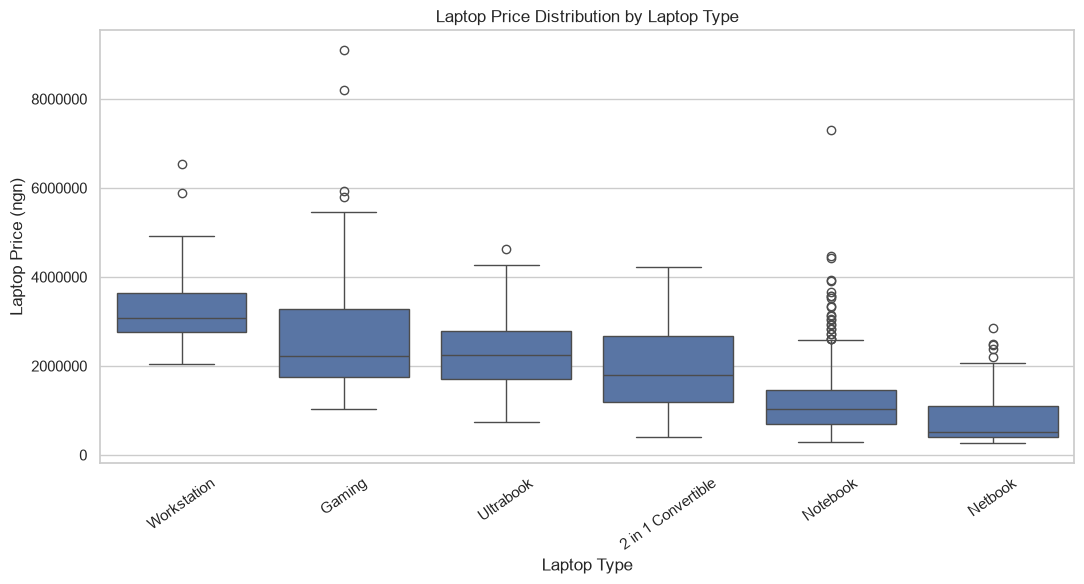

In [129]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='TypeName',
    y='price_ngn',
    order=type_price.index
)

plt.title('Laptop Price Distribution by Laptop Type')
plt.xlabel('Laptop Type')
plt.ylabel('Laptop Price (ngn)')

plt.xticks(rotation=35)
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

In [130]:
# Calculate correlation between RAM and price
ram_price_correlation = df['ram_gb'].corr(df['price_ngn'])

print(
    f"Correlation between RAM and price: "
    f"{ram_price_correlation:.3f}"
)

Correlation between RAM and price: 0.743


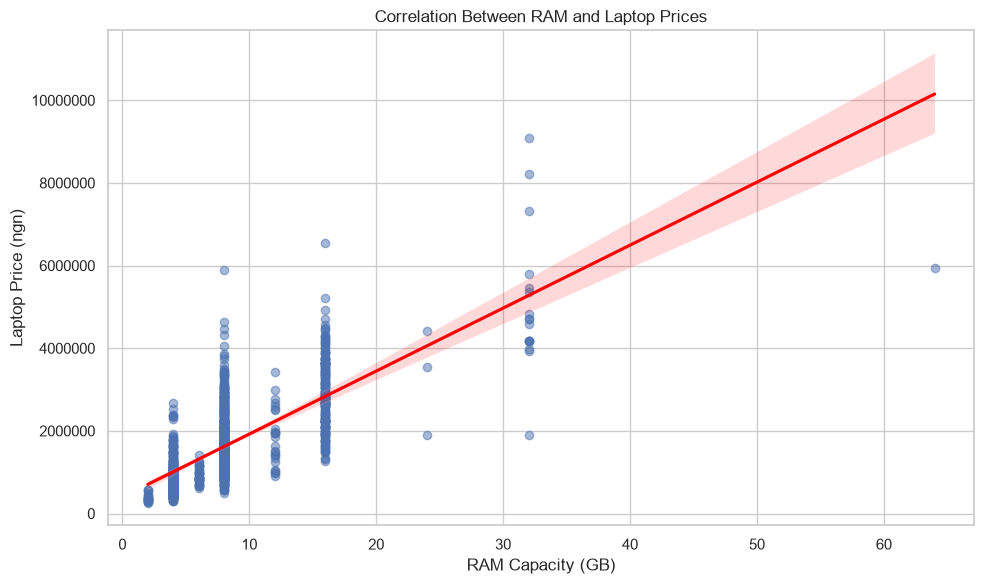

In [131]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='ram_gb',
    y='price_ngn',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)

plt.title('Correlation Between RAM and Laptop Prices')
plt.xlabel('RAM Capacity (GB)')
plt.ylabel('Laptop Price (ngn)')

plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

## 4. Findings from Bivariate Analysis

### RAM and Laptop Prices
The analysis showed a clear positive relationship between RAM capacity and laptop price. Laptop prices generally increased as RAM increased: the median price rose from ₦349,067.16 for 2 GB RAM to ₦1,639,422.26 for 8 GB, ₦2,820,134.47 for 16 GB, and ₦4,695,057.72 for 32 GB. The correlation coefficient was **0.743**, indicating a strong positive linear relationship between RAM and price.

### Processor and Laptop Prices
The processor analysis showed substantial differences in price distributions across processor manufacturers. Intel processors had a median price of ₦1,490,248.26 compared with ₦707,002.72 for AMD processors, while the only Samsung-powered laptop in the dataset had a price of ₦983,056.66. This suggests that processor manufacturer is associated with price, although the small Samsung sample limits that comparison. Intel laptops also represented the majority of the dataset with 1,240 observations.

### Storage and Laptop Prices
The storage analysis showed that configurations containing large or multiple solid-state drives generally had higher prices. A 1 TB SSD had a median price of ₦3,926,259.68, while a 512 GB SSD had a median of ₦2,788,807.93 and a 256 GB SSD had a median of ₦1,688,649.68. By contrast, 1 TB HDD systems had a median of ₦908,469.66 and 32 GB flash-storage systems had a median of ₦421,416.55. The highest median among configurations with at least 10 observations was therefore associated with 1 TB SSDs, and adding SSD capacity or combining SSDs with HDD storage was associated with higher prices.

### Laptop Brand and Prices
Laptop prices varied substantially across manufacturers. Razer had the highest median price at ₦4,324,554.26, followed by LG at ₦3,131,162.26 and MSI at ₦2,385,292.26. Vero had the lowest median price at ₦308,566.42, followed by Mediacom at ₦395,311.10 and Acer at ₦833,882.66.

### Laptop Type and Prices
The comparison of laptop categories showed clear price differences. Workstations had the highest median price at ₦3,080,293.93, followed by Ultrabooks at ₦2,236,118.26 and Gaming laptops at ₦2,226,869.47. Netbooks had the lowest median price at ₦507,191.60, while Notebooks had a median of ₦1,030,792.34. This suggests that laptop category is useful when estimating laptop prices.

### Overall Interpretation
The bivariate analysis identified several relationships between laptop specifications and prices. RAM showed the strongest numeric relationship with price, while processor brand, storage configuration, manufacturer and laptop type also showed meaningful differences in price distributions. These findings provide useful information for feature selection and subsequent machine learning model development.

## 5. Outlier Detection and Investigation

This stage investigates unusually low and high laptop prices in the dataset. Outlier detection helps identify values that differ significantly from the general price distribution.

The Interquartile Range (IQR) method will be used to identify potential price outliers. These observations will be examined before any decision is made about retaining or removing them.

In [132]:
# Calculate the first and third quartiles
Q1 = df['price_ngn'].quantile(0.25)
Q3 = df['price_ngn'].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Determine the lower and upper boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("First Quartile (Q1):", Q1)
print("Third Quartile (Q3):", Q3)
print("Interquartile Range (IQR):", IQR)
print("Lower Boundary:", lower_bound)
print("Upper Boundary:", upper_bound)

First Quartile (Q1): 893552.26
Third Quartile (Q3): 2219530.11
Interquartile Range (IQR): 1325977.8499999999
Lower Boundary: -1095414.515
Upper Boundary: 4208496.885


In [133]:
# Identify potential price outliers
outliers = df[
    (df['price_ngn'] < lower_bound) |
    (df['price_ngn'] > upper_bound)
]

print("Total observations:", len(df))
print("Potential outliers:", len(outliers))
print("Percentage of outliers:", round((len(outliers) / len(df)) * 100, 2), "%")

Total observations: 1303
Potential outliers: 29
Percentage of outliers: 2.23 %


In [134]:
outliers[
    ['Company', 'Product', 'TypeName', 'Ram',
     'Cpu', 'Memory', 'price_ngn']
].sort_values(by='price_ngn', ascending=False)

,Company,Product,TypeName,Ram,Cpu,Memory,price_ngn
196,Razer,Blade Pro,Gaming,32GB,Intel Core i7 7820HK 2.9GHz,1TB SSD,9098122.26
830,Razer,Blade Pro,Gaming,32GB,Intel Core i7 7820HK 2.9GHz,512GB SSD,8203078.26
610,Lenovo,Thinkpad P51,Notebook,32GB,Intel Xeon E3-1535M v6 3.1GHz,1TB SSD,7308034.26
749,HP,Zbook 17,Workstation,16GB,Intel Xeon E3-1535M v5 2.9GHz,256GB SSD,6547246.86
1066,Asus,ROG G701VO,Gaming,64GB,Intel Core i7 6820HK 2.7GHz,1TB SSD,5929666.50
1136,HP,ZBook 17,Workstation,8GB,Intel Core i7 6700HQ 2.6GHz,256GB SSD,5891477.96
238,Asus,ROG G703VI-E5062T,Gaming,32GB,Intel Core i7 7820HK 2.9GHz,512GB SSD + 1TB HDD,5802868.60
723,Dell,Alienware 17,Gaming,32GB,Intel Core i7 7700HQ 2.8GHz,1TB SSD + 1TB HDD,5458873.36
780,Dell,Alienware 17,Gaming,32GB,Intel Core i7 7700HQ 2.8GHz,1TB SSD + 1TB HDD,5353556.51
1231,Razer,Blade Pro,Gaming,16GB,Intel Core i7 7700HQ 2.8GHz,1TB SSD,5219598.26


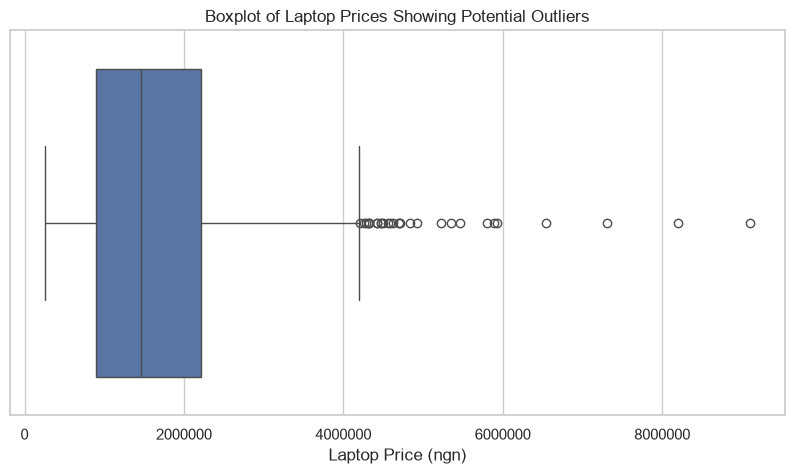

In [135]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['price_ngn'])

plt.title('Boxplot of Laptop Prices Showing Potential Outliers')
plt.xlabel('Laptop Price (ngn)')

plt.ticklabel_format(style='plain', axis='x')
plt.show()

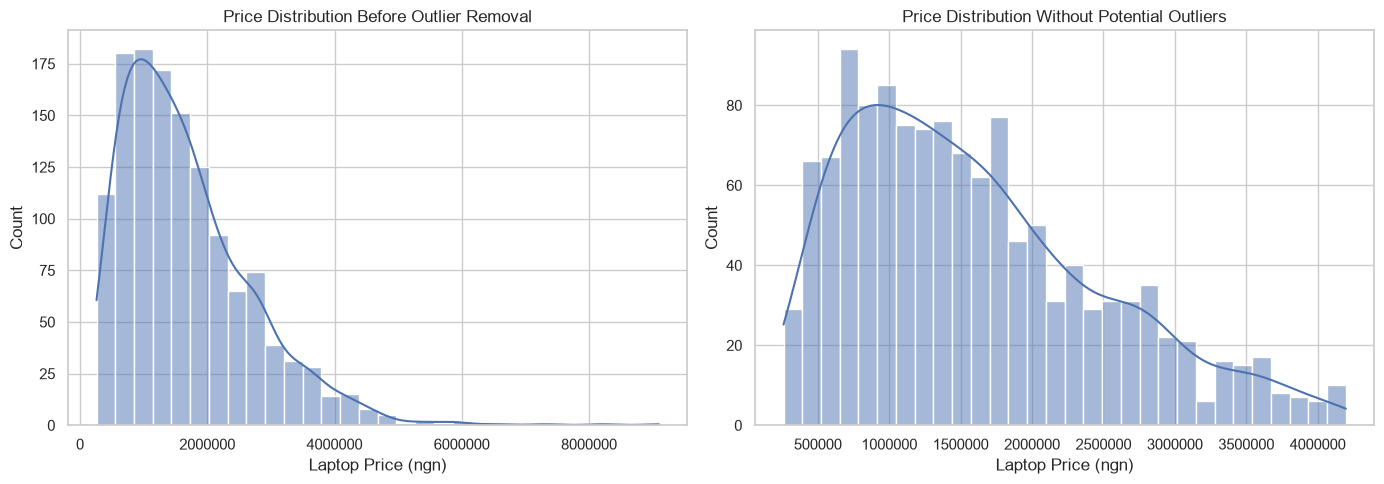

In [136]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original price distribution
sns.histplot(df['price_ngn'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Price Distribution Before Outlier Removal')
axes[0].set_xlabel('Laptop Price (ngn)')
axes[0].ticklabel_format(style='plain', axis='x')

# Price distribution without potential outliers
sns.histplot(
    df.loc[~df.index.isin(outliers.index), 'price_ngn'],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title('Price Distribution Without Potential Outliers')
axes[1].set_xlabel('Laptop Price (ngn)')
axes[1].ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.show()

In [137]:
print("Original Dataset Statistics")
print(df['price_ngn'].describe())

print("\nPotential Outlier Statistics")
print(outliers['price_ngn'].describe())

Original Dataset Statistics
count    1.303000e+03
mean     1.676249e+06
std      1.042740e+06
min      2.595628e+05
25%      8.935523e+05
50%      1.457430e+06
75%      2.219530e+06
max      9.098122e+06
Name: price_ngn, dtype: float64

Potential Outlier Statistics
count    2.900000e+01
mean     5.187422e+06
std      1.221881e+06
min      4.212674e+06
25%      4.427484e+06
50%      4.695058e+06
75%      5.458873e+06
max      9.098122e+06
Name: price_ngn, dtype: float64


In [138]:
df.nlargest(5, 'price_ngn')[
    ['Company', 'Product', 'Ram', 'Cpu', 'Memory', 'price_ngn']
]

,Company,Product,Ram,Cpu,Memory,price_ngn
196,Razer,Blade Pro,32GB,Intel Core i7 7820HK 2.9GHz,1TB SSD,9098122.26
830,Razer,Blade Pro,32GB,Intel Core i7 7820HK 2.9GHz,512GB SSD,8203078.26
610,Lenovo,Thinkpad P51,32GB,Intel Xeon E3-1535M v6 3.1GHz,1TB SSD,7308034.26
749,HP,Zbook 17,16GB,Intel Xeon E3-1535M v5 2.9GHz,256GB SSD,6547246.86
1066,Asus,ROG G701VO,64GB,Intel Core i7 6820HK 2.7GHz,1TB SSD,5929666.50


## 6. Final Exploratory Data Analysis Summary

This section summarizes the major findings from the exploratory data analysis. It highlights important relationships between laptop specifications and prices, identifies potentially useful predictive features, and provides recommendations for the subsequent machine learning development stage.

In [139]:
# Display the final dataset dimensions
print("Total number of records:", df.shape[0])
print("Total number of features:", df.shape[1])

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Total number of records: 1303
Total number of features: 15

Dataset Columns:
['laptop_ID', 'Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'price_ngn', 'ram_gb', 'processor_brand']

Missing Values:
0

Duplicate Records:
0


In [140]:
# Summary of numerical variables
df[['Inches', 'ram_gb', 'price_ngn']].describe()

,Inches,ram_gb,price_ngn
count,1303.000000,1303.000000,1.303000e+03
mean,15.017191,8.382195,1.676249e+06
std,1.426304,5.084665,1.042740e+06
min,10.100000,2.000000,2.595628e+05
25%,14.000000,4.000000,8.935523e+05
50%,15.600000,8.000000,1.457430e+06
75%,15.600000,8.000000,2.219530e+06
max,18.400000,64.000000,9.098122e+06


In [141]:
# Examine the distribution of important categorical variables

categorical_features = [
    'Company',
    'TypeName',
    'processor_brand',
    'Memory',
    'OpSys'
]

for feature in categorical_features:
    print(f"\n{feature} Distribution:")
    print(df[feature].value_counts().head(10))


Company Distribution:
Company
Dell       297
Lenovo     297
HP         274
Asus       158
Acer       103
MSI         54
Toshiba     48
Apple       21
Samsung      9
Razer        7
Name: count, dtype: int64

TypeName Distribution:
TypeName
Notebook              727
Gaming                205
Ultrabook             196
2 in 1 Convertible    121
Workstation            29
Netbook                25
Name: count, dtype: int64

processor_brand Distribution:
processor_brand
Intel      1240
AMD          62
Samsung       1
Name: count, dtype: int64

Memory Distribution:
Memory
256GB SSD               412
1TB HDD                 223
500GB HDD               132
512GB SSD               118
128GB SSD +  1TB HDD     94
128GB SSD                76
256GB SSD +  1TB HDD     73
32GB Flash Storage       38
2TB HDD                  16
64GB Flash Storage       15
Name: count, dtype: int64

OpSys Distribution:
OpSys
Windows 10      1072
No OS             66
Linux             62
Windows 7         45
Chrome OS  

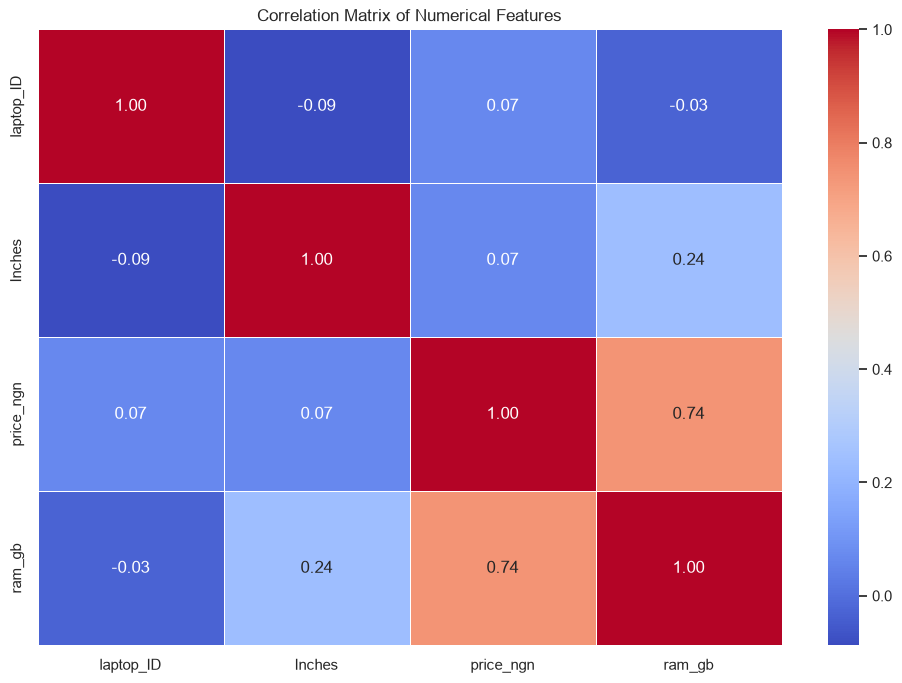

In [142]:
# Select numerical columns for correlation analysis
numerical_data = df.select_dtypes(include=['number'])

# Generate correlation matrix
correlation_matrix = numerical_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [143]:
# Suggested features for machine learning

selected_features = [
    'Company',
    'TypeName',
    'Inches',
    'ScreenResolution',
    'Cpu',
    'Ram',
    'Memory',
    'Gpu',
    'OpSys',
    'Weight'
]

target_variable = 'price_ngn'

print("Potential Input Features:")
for feature in selected_features:
    print("-", feature)

print("\nTarget Variable:")
print("-", target_variable)

Potential Input Features:
- Company
- TypeName
- Inches
- ScreenResolution
- Cpu
- Ram
- Memory
- Gpu
- OpSys
- Weight

Target Variable:
- price_ngn


In [144]:
# Create a separate dataset containing the selected features and target

eda_model_data = df[selected_features + [target_variable]].copy()

print("Model Dataset Shape:", eda_model_data.shape)

eda_model_data.head()

Model Dataset Shape: (1303, 11)


,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,price_ngn
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1998469.16
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,1340984.76
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,857750.50
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,3785215.66
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,2690502.26


## 6.1 Overall EDA Findings

The exploratory data analysis revealed several important patterns in the laptop dataset.

1. **RAM and Price:** RAM capacity showed a strong positive correlation with laptop price, with a correlation coefficient of 0.743.

2. **Processor and Price:** Laptop prices varied across processor manufacturers, with Intel-powered laptops representing the majority of the observations.

3. **Storage and Price:** Storage configurations containing larger SSD capacities generally showed higher median prices than lower-capacity or HDD-based configurations.

4. **Brand and Price:** Significant differences in median prices were observed across laptop manufacturers. Premium brands such as Razer recorded higher median prices.

5. **Laptop Type and Price:** Workstations, Ultrabooks and Gaming laptops generally recorded higher median prices than Netbooks and standard Notebooks.

6. **Outliers:** The IQR method identified 29 potential high-price outliers, representing 2.23% of the dataset. These records were retained pending further data-quality investigation.

Overall, the analysis suggests that laptop specifications, manufacturer and laptop category contain useful information for predicting laptop prices.

## 6.2 Recommendations for Machine Learning Development

Based on the exploratory data analysis, the following recommendations are made for the subsequent model development stage:

1. Use `price_ngn` as the target variable for price prediction.

2. Consider RAM, processor specifications, storage configuration, laptop manufacturer, laptop type, screen size, GPU, operating system and weight as potential predictive features.

3. Apply suitable encoding techniques to categorical variables before training machine learning models.

4. Convert numerical information embedded in text columns, such as RAM and weight, into appropriate numerical representations where necessary.

5. Investigate the potential influence of extreme price observations without automatically removing legitimate premium laptop records.

6. Evaluate multiple regression algorithms and compare their predictive performance using appropriate evaluation metrics such as Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R-squared.

7. Ensure that the dataset's suitability for estimating used laptop prices is verified, since the dataset's second-hand status has not yet been established.

In [145]:
print("Dataset Shape:", eda_model_data.shape)

print("\nMissing Values:")
print(eda_model_data.isnull().sum())

print("\nData Types:")
print(eda_model_data.dtypes)

print("\nDuplicate Rows:")
print(eda_model_data.duplicated().sum())

Dataset Shape: (1303, 11)

Missing Values:
Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
price_ngn           0
dtype: int64

Data Types:
Company                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                     str
Memory                  str
Gpu                     str
OpSys                   str
Weight                  str
price_ngn           float64
dtype: object

Duplicate Rows:
29
